# D4RT
### A video becomes a queryable 4D scene.

```python
d = d4rt(video)
p = d.query(u, v, t_src, t_tgt, t_cam)
```

**Choose a pixel. Choose a moment. Choose a camera.**

A 5–7 minute walkthrough of depth, correspondence, 3D motion, and reference frames
through one interface. This small Python wrapper uses
[OpenD4RT](https://github.com/Lijiaxin0111/Open-d4rt), an unofficial implementation of
[D4RT](https://d4rt-paper.github.io/).

> **Live GPU demo.** Before opening this notebook, run the setup commands in
> `README.md` to fetch OpenD4RT, its released 32-frame checkpoint, and the
> `juggle_5` WorldTrack example. This notebook does not download weights while presenting.
> Run all cells once before the talk and save the outputs. A separate executed
> `D4RT_rehearsal.ipynb` teaches the same API with explicitly labeled analytic geometry.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

ROOT = Path.cwd()
if not (ROOT / "d4rt_demo").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "d4rt_demo").is_dir():
    raise RuntimeError("Start Jupyter from the d4rt project directory.")
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)
from d4rt_demo import D4RT, load_video, pixel_grid
from d4rt_demo import visuals as viz
viz.style()
display(HTML('''<style>
  .jp-RenderedHTMLCommon h1 {font-size:52px; letter-spacing:-2px; color:#20bfa9}
  .jp-RenderedHTMLCommon h2 {font-size:30px; letter-spacing:-.5px}
  .jp-RenderedHTMLCommon p, .jp-RenderedHTMLCommon li {font-size:17px; line-height:1.65}
  .jp-RenderedHTMLCommon blockquote {border-left:4px solid #20bfa9; padding:8px 20px}
  .jp-RenderedHTMLCommon pre {border-radius:10px; padding:20px}
</style>'''))

In [2]:
# Configuration — prepare this cell before the presentation.
BACKEND = 'opend4rt'
VIDEO_PATH = ROOT / "data/worldtrack/pstudio_mini/juggle_5.npz"
CHECKPOINT_DIR = ROOT / "checkpoints/OpenD4RT_32CLIP_9Dataset_NoAUG"
N_FRAMES = 32
STRIDE = 2  # Every other original frame; query indices always refer to this sampled clip.

if BACKEND == "opend4rt":
    video = load_video(VIDEO_PATH, max_frames=N_FRAMES, stride=STRIDE)
    d4rt = D4RT.from_pretrained(
        repo_dir=ROOT / ".cache/Open-d4rt",
        checkpoint=CHECKPOINT_DIR / "opend4rt.ckpt",
        config=CHECKPOINT_DIR / "model.yaml",
        device="cuda", precision="float32", chunk_size=64,  # auto trades precision for lower VRAM.
    )
    source_uv = np.array([.62, .65])  # Visible shirt patch in juggle_5, frame 0.
    anchors = np.array([[.62,.65], [.63,.43], [.56,.86], [.597,.475], [.23,.48], [.80,.30]])
elif BACKEND == "illustration":
    from d4rt_demo.illustration import make_illustration
    video = make_illustration(n_frames=N_FRAMES)
    d4rt = D4RT.illustration()
    source_uv = np.array([.32, .49])
    anchors = np.array([[.32,.49], [.36,.55], [.28,.45], [.55,.5], [.75,.25], [.18,.72]])
else:
    raise ValueError("Select opend4rt or illustration explicitly.")

print(f"{BACKEND} | {video.name} | {len(video)} frames | RGB {video.frames.shape[2]}×{video.frames.shape[1]}")

opend4rt | juggle_5 | 32 frames | RGB 640×360


## 01 · Encode once. Ask many questions.

The encoder processes the clip into a global scene representation.
Each subsequent query uses those cached features and the source pixel's local RGB patch.

*Say: “The expensive part happens here. From now on, I’m asking questions about the same video.”*


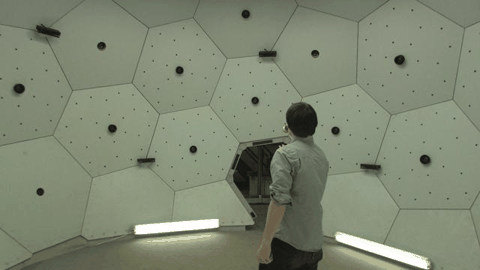

In [3]:
d = d4rt(video)
viz.banner(d)
viz.video_player(video)

## 02 · The whole interface

```python
d.query(u, v, t_src, t_tgt, t_cam)
```

| Argument | Question |
|:--|:--|
| `u, v` | Which source pixel? Normalized coordinates in `[0, 1]`. |
| `t_src` | In which frame do I identify that physical point? |
| `t_tgt` | At which frame do I want its position? |
| `t_cam` | In which frame's camera coordinates should the 3D answer be expressed? |

All frame indices are **zero based** and refer to the sampled input clip.
The result contains `xyz`, target-frame `uv`, a visibility score, and a raw confidence head.
`xyz` uses the model's learned scale; it is not a calibrated distance measurement in meters.

*Say: “Source time identifies the point. Target time chooses its state. Camera time chooses the coordinate system.”*

3D position: [0.021  0.2476 2.6203]
Visibility: 0.958


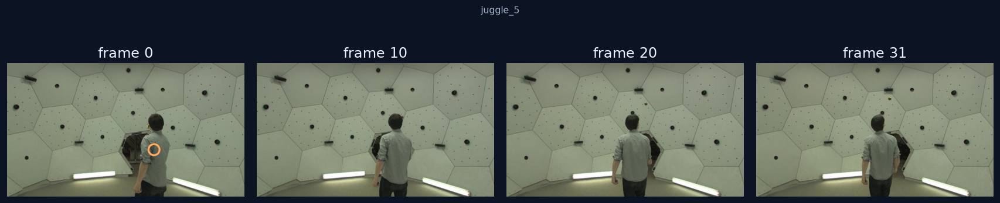

In [4]:
u, v = source_uv
t_src, t_tgt, t_cam = 0, len(video) - 1, 0

p = d.query(u, v, t_src, t_tgt, t_cam)
print("3D position:", np.round(p.xyz, 4))
print("Visibility:", round(float(p.visibility), 3))
viz.filmstrip(video, source_uv)

## 03 · Depth is one query pattern

Ask about each pixel **at its own time, in its own camera**. Keep the Z coordinate.
We sample a grid for speed; increasing its resolution asks more of the same queries.

*Say: “There isn’t a new depth model here. I’ve only changed the arguments.”*

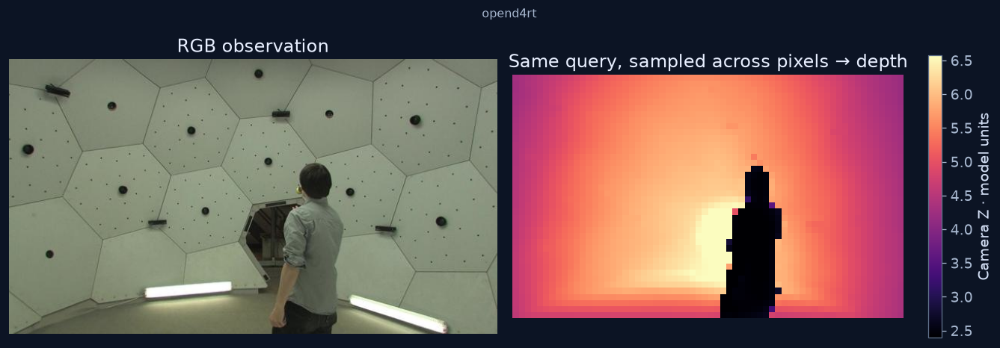

In [5]:
U, V = pixel_grid(cols=64, rows=40, margin=0.0)
t = 0
surface = d.query(U, V, t_src=t, t_tgt=t, t_cam=t)
depth = surface.depth

viz.depth_view(video, surface, t)

## 04 · A point becomes a 3D trajectory

Hold the source point fixed. Sweep target time. Hold camera 0 as the shared reference.
Scalar and array arguments broadcast just like NumPy, so a batch of points and times is one call.

For 2D overlays, query again with `t_cam=t_tgt`, matching OpenD4RT's local-camera inference.
Visibility is the sigmoid of the model's visibility logit; it is not a guarantee of correctness.

*Say: “It can return a position even when the point is occluded. The visibility output tells us whether it is seen.”*

points × times × xyz: (6, 32, 3)


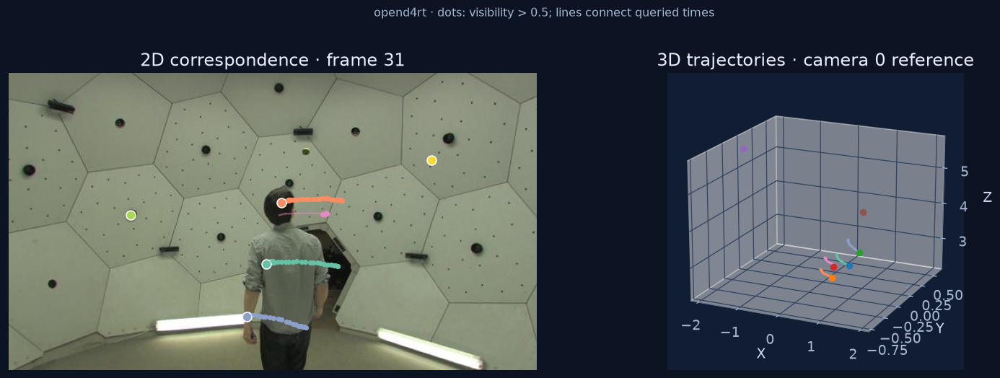

In [6]:
times = np.arange(len(video))
u = anchors[:, 0, None]
v = anchors[:, 1, None]

tracks = d.query(u, v, t_src=0, t_tgt=times, t_cam=0)
local = d.query(u, v, t_src=0, t_tgt=times, t_cam=times)

print("points × times × xyz:", tracks.xyz.shape)
viz.track_view(video, anchors, tracks, local, times)

## 05 · Scene time and camera time are independent

The same trajectory can be expressed in camera 0 coordinates, or in each target camera's coordinates.
A fixed reference makes the object's trajectory comparable across time. A moving camera reference also
reflects camera motion. Camera 0 is a convenient reference, not an externally calibrated world frame.

The `juggle_5` capture has a largely fixed camera, so both references may look similar here.
A clip with a moving camera makes this difference more visible.

These are direct predictions in the requested frame, so this wrapper does not estimate camera poses
and transform the 3D answer afterward. Independently decoded coordinates can have consistency errors.

*Say: “This is the subtle part: when does the point exist, and from whose camera do I describe it?”*

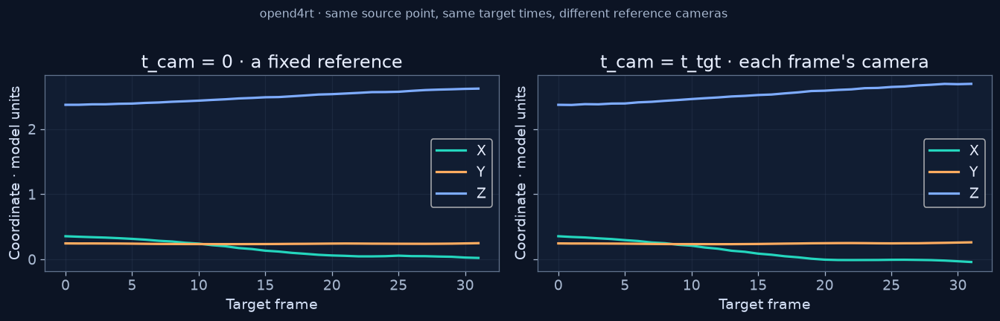

Same physical instant expressed in 32 camera frames.
First and last reference: [[0.119 0.235 2.49 ]
 [0.065 0.247 2.561]]


In [7]:
# tracks and local differ only in t_cam. Compare the same point.
viz.camera_view(tracks, local, times, point=0)

# Freeze the physical instant; change only the reference camera.
t = len(video) // 2
camera_sweep = d.query(*source_uv, t_src=0, t_tgt=t, t_cam=times)
print("Same physical instant expressed in", len(camera_sweep.xyz), "camera frames.")
print("First and last reference:", np.round(camera_sweep.xyz[[0, -1]], 3))

## 06 · Scale the same idea to a 4D surface

Track a grid of source pixels through time in one shared reference. Drag to rotate, then move the time slider.
Colors come from the source RGB pixels. Low-visibility points are shown faintly.

This is a **sampled first-frame surface**, not a complete reconstruction of surfaces hidden in that frame.
Tracking all pixels is the same query pattern at a larger sampling budget.
The player below uses saved predictions; rotating and scrubbing it require no GPU.

*Say: “The data structure didn’t change. We asked more questions and got a surface moving through time.”*

In [8]:
U, V = pixel_grid(cols=36, rows=24)
cloud_times = np.unique(np.linspace(0, len(video) - 1, 16, dtype=int))
cloud = d.query(
    U.reshape(-1, 1), V.reshape(-1, 1),
    t_src=0, t_tgt=cloud_times, t_cam=0,
)
colors = viz.sample_colors(video, U, V)
player_path = viz.scene_player(cloud, colors, cloud_times,
                               path=f"artifacts/{BACKEND}_4d_scene.html")
print("Standalone offline player:", player_path)

<iframe title="Interactive 4D scene" style="width:100%;height:660px;border:0;border-radius:12px" srcdoc="<!doctype html>
<html>
<head>
 <meta charset="utf-8" />
 <style>html, body {height: 100%;}</style>
</head>
<body>
 <div style="height:620px; width:100%;"> <script>window.PlotlyConfig = {MathJaxConfig: 'local'};</script>
 <script>/**
* plotly.js v4.1.1
* Copyright 2012-2026, Plotly, Inc.
* All rights reserved.
* Licensed under the MIT license
*/
(
 function(root, factory) {
 if (typeof module === "object" && module.exports) {
 module.exports = factory();
 } else {
 root.moduleName = factory();
 }
} (typeof self !== "undefined" ? self : this, () => {
"use strict";var Plotly=(()=>{var B1t=Object.create;var S6=Object.defineProperty,q1t=Object.defineProperties,O1t=Object.getOwnPropertyDescriptor,N1t=Object.getOwnPropertyDescriptors,U1t=Object.getOwnPropertyNames,tC=Object.getOwnPropertySymbols,V1t=Object.getPrototypeOf,pN=Object.prototype.hasOwnProperty,Vse=Object.prototype.propertyIsEnumerable;var dN=(e,t)=>(t=Symbol[e])?t:Symbol.for("Symbol."+e),G1t=e=>{throw TypeError(e)};var Use=(e,t,r)=>t in e?S6(e,t,{enumerable:!0,configurable:!0,writable:!0,value:r}):e[t]=r,fn=(e,t)=>{for(var r in t||(t={}))pN.call(t,r)&&Use(e,r,t[r]);if(tC)for(var r of tC(t))Vse.call(t,r)&&Use(e,r,t[r]);return e},ma=(e,t)=>q1t(e,N1t(t));var Gse=(e,t)=>{var r={};for(var i in e)pN.call(e,i)&&t.indexOf(i)<0&&(r[i]=e[i]);if(e!=null&&tC)for(var i of tC(e))t.indexOf(i)<0&&Vse.call(e,i)&&(r[i]=e[i]);return r};var Ea=(e,t,r)=>()=>{if(r)throw r[0];try{return e&&(t=e(e=0)),t}catch(i){throw r=[i],i}};var W=(e,t)=>()=>{try{return t||e((t={exports:{}}).exports,t),t.exports}catch(r){throw t=0,r}},Fp=(e,t)=>{for(var r in t)S6(e,r,{get:t[r],enumerable:!0})},Hse=(e,t,r,i)=>{if(t&&typeof t=="object"||typeof t=="function")for(let n of U1t(t))!pN.call(e,n)&&n!==r&&S6(e,n,{get:()=>t[n],enumerable:!(i=O1t(t,n))||i.enumerable});return e};var nd=(e,t,r)=>(r=e!=null?B1t(V1t(e)):{},Hse(t||!e||!e.__esModule?S6(r,"default",{value:e,enumerable:!0}):r,e)),Go=e=>Hse(S6({},"__esModule",{value:!0}),e);var Ki=(e,t,r)=>new Promise((i,n)=>{var a=l=>{try{s(r.next(l))}catch(u){n(u)}},o=l=>{try{s(r.throw(l))}catch(u){n(u)}},s=l=>l.done?i(l.value):Promise.resolve(l.value).then(a,o);s((r=r.apply(e,t)).next())}),H1t=function(e,t){this[0]=e,this[1]=t};var jse=e=>{var t=e[dN("asyncIterator")],r=!1,i,n={};return t==null?(t=e[dN("iterator")](),i=a=>n[a]=o=>t[a](o)):(t=t.call(e),i=a=>n[a]=o=>{if(r){if(r=!1,a==="throw")throw o;return o}return r=!0,{done:!1,value:new H1t(new Promise(s=>{var l=t[a](o);l instanceof Object||G1t("Object expected"),s(l)}),1)}}),n[dN("iterator")]=()=>n,i("next"),"throw"in t?i("throw"):n.throw=a=>{throw a},"return"in t&&i("return"),n};var E6=W($se=>{"use strict";$se.version="4.1.1"});var Yse=W((Wse,rC)=>{(function(t,r,i){r[t]=r[t]||i(),typeof rC!="undefined"&&rC.exports&&(rC.exports=r[t])})("Promise",typeof window!="undefined"?window:Wse,function(){"use strict";var t,r,i,n=Object.prototype.toString,a=typeof setImmediate!="undefined"?function(w){return setImmediate(w)}:setTimeout;try{Object.defineProperty({},"x",{}),t=function(w,b,_,M){return Object.defineProperty(w,b,{value:_,writable:!0,configurable:M!==!1})}}catch(g){t=function(b,_,M){return b[_]=M,b}}i=(function(){var w,b,_;function M(x,T){this.fn=x,this.self=T,this.next=void 0}return{add:function(T,A){_=new M(T,A),b?b.next=_:w=_,b=_,_=void 0},drain:function(){var T=w;for(w=b=r=void 0;T;)T.fn.call(T.self),T=T.next}}})();function o(g,w){i.add(g,w),r||(r=a(i.drain))}function s(g){var w,b=typeof g;return g!=null&&(b=="object"||b=="function")&&(w=g.then),typeof w=="function"?w:!1}function l(){for(var g=0;g<this.chain.length;g++)u(this,this.state===1?this.chain[g].success:this.chain[g].failure,this.chain[g]);this.chain.length=0}function u(g,w,b){var _,M;try{w===!1?b.reject(g.msg):(w===!0?_=g.msg:_=w.call(void 0,g.msg),_===b.promise?b.reject(TypeError("Promise-chain cycle")):(M=s(_))?M.call(_,b.resolve,b.reject):b.resolve(_))}ca

Standalone offline player: artifacts/opend4rt_4d_scene.html


## 07 · Random access, including backward in time

Source time does not have to be frame 0. We can identify a point in a later frame and ask about an earlier one.
Target frames must remain within the supplied clip: this notebook demonstrates reconstruction from the full
observed video, not causal forecasting beyond it.

The decoder handles queries independently. Changing a query's order or its batch companions should not
materially change its answer; minor floating point differences are expected.

In [9]:
backward = d.query(.62, .65, t_src=len(video) - 1, t_tgt=0, t_cam=0)
print("Later-frame point, earlier-time position:", np.round(backward.xyz, 4))

# Demonstrate that the same encoded scene supports out-of-order queries.
query_times = np.array([len(video)-1, 0, len(video)//2])
batch = d.query(*source_uv, t_src=0, t_tgt=query_times, t_cam=0)
alone = d.query(*source_uv, t_src=0, t_tgt=int(query_times[0]), t_cam=0)
print("Single vs batch max |Δxyz|:", float(np.max(np.abs(alone.xyz - batch.xyz[0]))))
print("Encoder calls:", d.stats["encoder_calls"], "| Queries answered:", d.stats["queries"])
if d.backend == "opend4rt":
    print("Measured encode seconds:", round(d.stats["encode_seconds"], 2))
    print("Measured decode seconds:", round(d.stats["decode_seconds"], 2))

Later-frame point, earlier-time position: [0.9055 0.6833 6.4818]
Single vs batch max |Δxyz|: 2.0116567611694336e-07
Encoder calls: 1 | Queries answered: 16806
Measured encode seconds: 0.79
Measured decode seconds: 5.23


## The takeaway

| What we want | What we vary |
|:--|:--|
| Depth | Sweep pixels; `t_src = t_tgt = t_cam`; read Z |
| 3D tracking | Fix a source point; sweep `t_tgt` |
| A common reference frame | Hold `t_cam` fixed |
| A moving camera reference | Set `t_cam = t_tgt` |
| 4D surface tracking | Sweep pixels **and** target time |

**One encoded video. Independently decoded queries. Several geometric tasks.**

D4RT's distinctive design is the queryable 3D representation and its separation of source, target,
and camera time. This demo illustrates that design; it does not establish a quality or speed comparison
with other methods. OpenD4RT and the original D4RT model have different checkpoints and reported results.

## Optional · Ask your own question

Adjust the pixel and three time indices, then press **Query this point**.
This section needs a running Python kernel; the saved 4D player above also works offline.

In [ ]:
viz.query_explorer(d, *source_uv)

## Optional · Save tonight's results

Run this before presenting to create a portable player and a NumPy archive of the queries shown above.
The archive records its backend so illustration data cannot be mistaken for model inference.

In [11]:
import json
output = ROOT / "artifacts"
output.mkdir(exist_ok=True)
metadata = {
    "backend": d.backend, "video": video.name, "frames": len(video),
    "source_commit": "403290a6e7ea6262a1f20f8c02d5461cd7b6c9b3",
    "checkpoint_revision": "7099b1fc760475de3b7409acd6b63f801b015d07" if d.backend == "opend4rt" else None,
    "original_indices": video.original_indices.tolist() if video.original_indices is not None else None,
    "stats": d.stats,
}
np.savez_compressed(output / f"{BACKEND}_results.npz",
    metadata=json.dumps(metadata), frames=video.frames,
    depth=depth, anchors=anchors, times=times,
    tracks_xyz=tracks.xyz, local_xyz=local.xyz, tracks_uv=local.uv,
    visibility=local.visibility, cloud_xyz=cloud.xyz,
    cloud_visibility=cloud.visibility, cloud_times=cloud_times, colors=colors)
(output / f"{BACKEND}_provenance.json").write_text(json.dumps(metadata, indent=2))
print("Saved", output / f"{BACKEND}_results.npz")

Saved /home/henrytan/git/d4rt/artifacts/opend4rt_results.npz


### Sources and attribution

- [Original D4RT project and paper](https://d4rt-paper.github.io/): the query formulation and task patterns.
- [OpenD4RT repository](https://github.com/Lijiaxin0111/Open-d4rt): unofficial PyTorch model and inference conventions.
- [Released checkpoint](https://huggingface.co/Lijiaxin0111/OpenD4RT): 32CLIP / 9Dataset / NoAUG.
- [WorldTrack release linked by OpenD4RT](https://drive.google.com/drive/folders/1-JW88ru30irMYyFab_4YBQbGbd9tKpXV):
  `pstudio_mini/juggle_5.npz`. Only its JPEG images are passed to the model; no ground-truth geometry is used.

This notebook's convenience API is local demo code. The original paper, third-party implementation,
checkpoints, and dataset retain their respective licenses and terms.